# Week 2 — Degree of Urbanization findings (presentation plots)

**Question:** Does residential vs non-residential behave the same in the city, the suburbs, and the countryside?

Run the cells below — each plot renders inline so you can **right-click → Copy Image** (or drag) into slides/docs.

Source analysis: `notebooks/09_week2_ghsl_degree_of_urbanization.ipynb` 
Artifacts: `outputs/week2_ghsl_dou/`


In [1]:
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

OUT = ROOT / "outputs" / "week2_ghsl_dou"
assert OUT.exists(), f"Missing {OUT} — run notebook 09 first."

PLOTS = {
    "1_core": OUT / "core_is_urban.png",
    "2_maps": OUT / "hinterland_maps_by_dou.png",
    "3_fill": OUT / "fill_rate_story.png",
    "4_f1": OUT / "f1_by_dou_and_city.png",
}
for k, p in PLOTS.items():
    assert p.exists(), f"Missing {p}"

print("ROOT:", ROOT)
print("OUT:", OUT)
for k, p in PLOTS.items():
    print(f"  {k}: {p.name} ({p.stat().st_size // 1024} KB)")


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou
  1_core: core_is_urban.png (116 KB)
  2_maps: hinterland_maps_by_dou.png (981 KB)
  3_fill: fill_rate_story.png (146 KB)
  4_f1: f1_by_dou_and_city.png (133 KB)


## Plot 1 — Downtown sample was almost entirely urban

Notebook 02’s tight metro cores are **98.7% urban**. Last week’s LORO F1 is an **urban-core** number — it cannot answer urban → rural until hinterland is included.


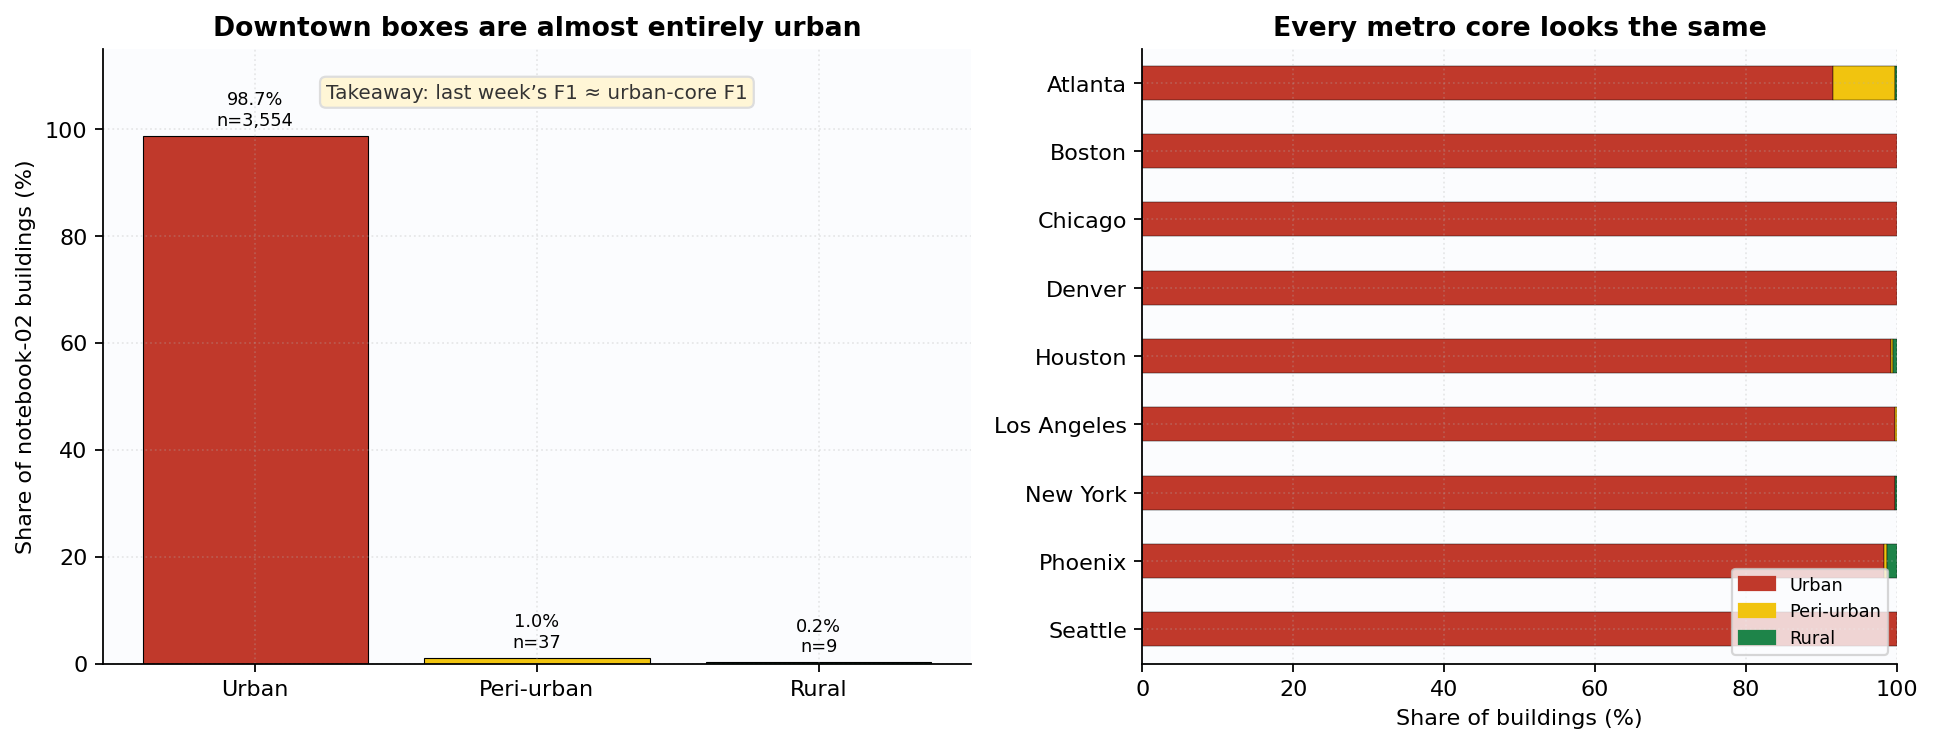

/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/core_is_urban.png


In [2]:
display(Image(filename=str(PLOTS["1_core"])))
print(PLOTS["1_core"])


## Plot 2 — Expanding the box brings in suburbs and countryside

Small black rectangle = last week’s downtown; larger area = hinterland. Gold = peri-urban, green = rural. Atlanta has a wide suburban ring; LA’s expanded box stays mostly urban.


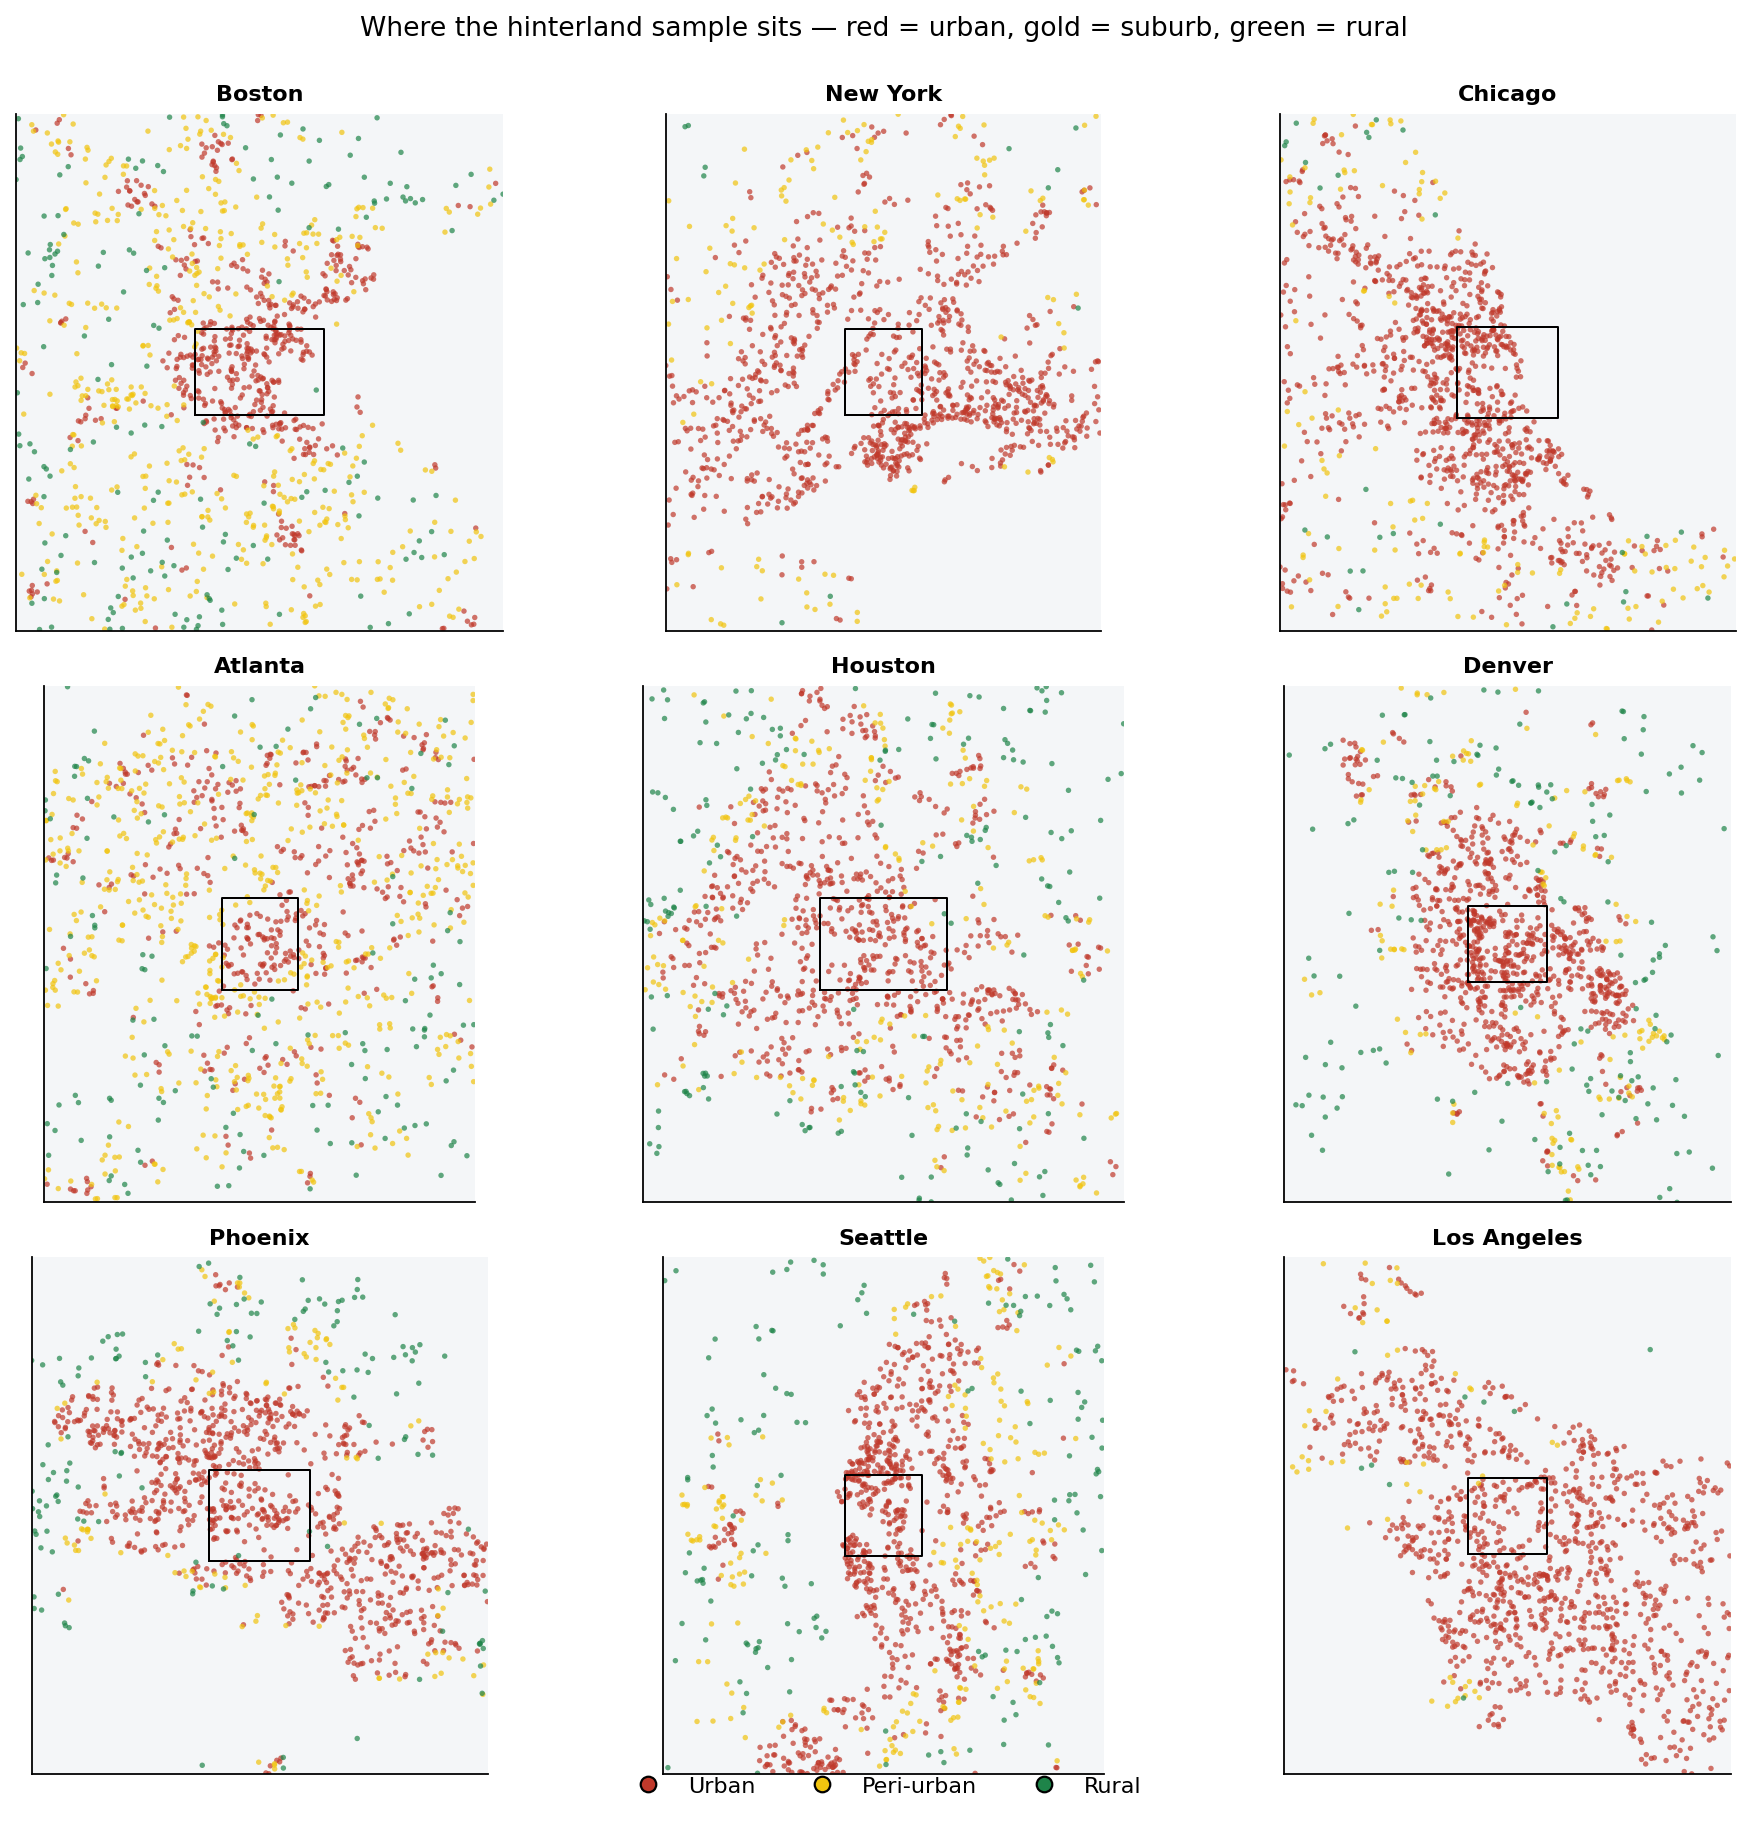

/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/hinterland_maps_by_dou.png


In [3]:
display(Image(filename=str(PLOTS["2_maps"])))
print(PLOTS["2_maps"])


## Plot 3 — Overture tags get rarer outside the city

Fill rate **35% → 20% → 14%** (urban → peri-urban → rural). Rural ground truth is thinner. Among tagged buildings, residential still dominates (~84–92%). Unlabeled footprints stay excluded.


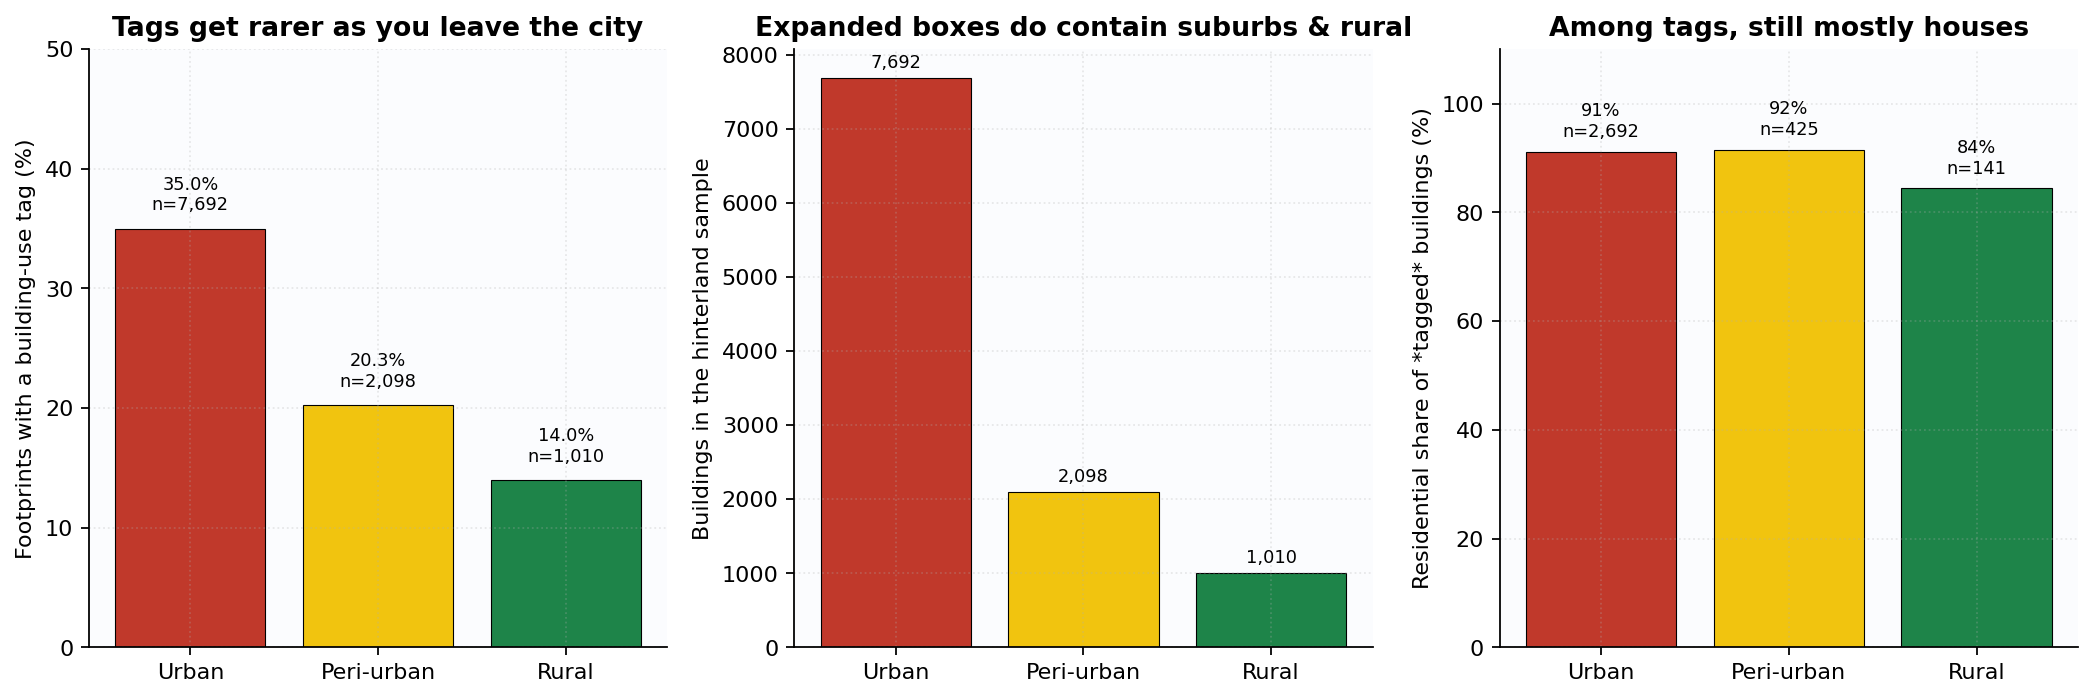

/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/fill_rate_story.png


In [4]:
display(Image(filename=str(PLOTS["3_fill"])))
print(PLOTS["3_fill"])


## Plot 4 — Classifier holds with a mild urban → rural drop

LORO macro-F1 **0.78 → 0.76 → 0.74**. Training on urban-only hurts rural most (0.74 → 0.71). Rural n is small — treat as directional. City holdout still varies (LA ~0.85 … NYC ~0.63).


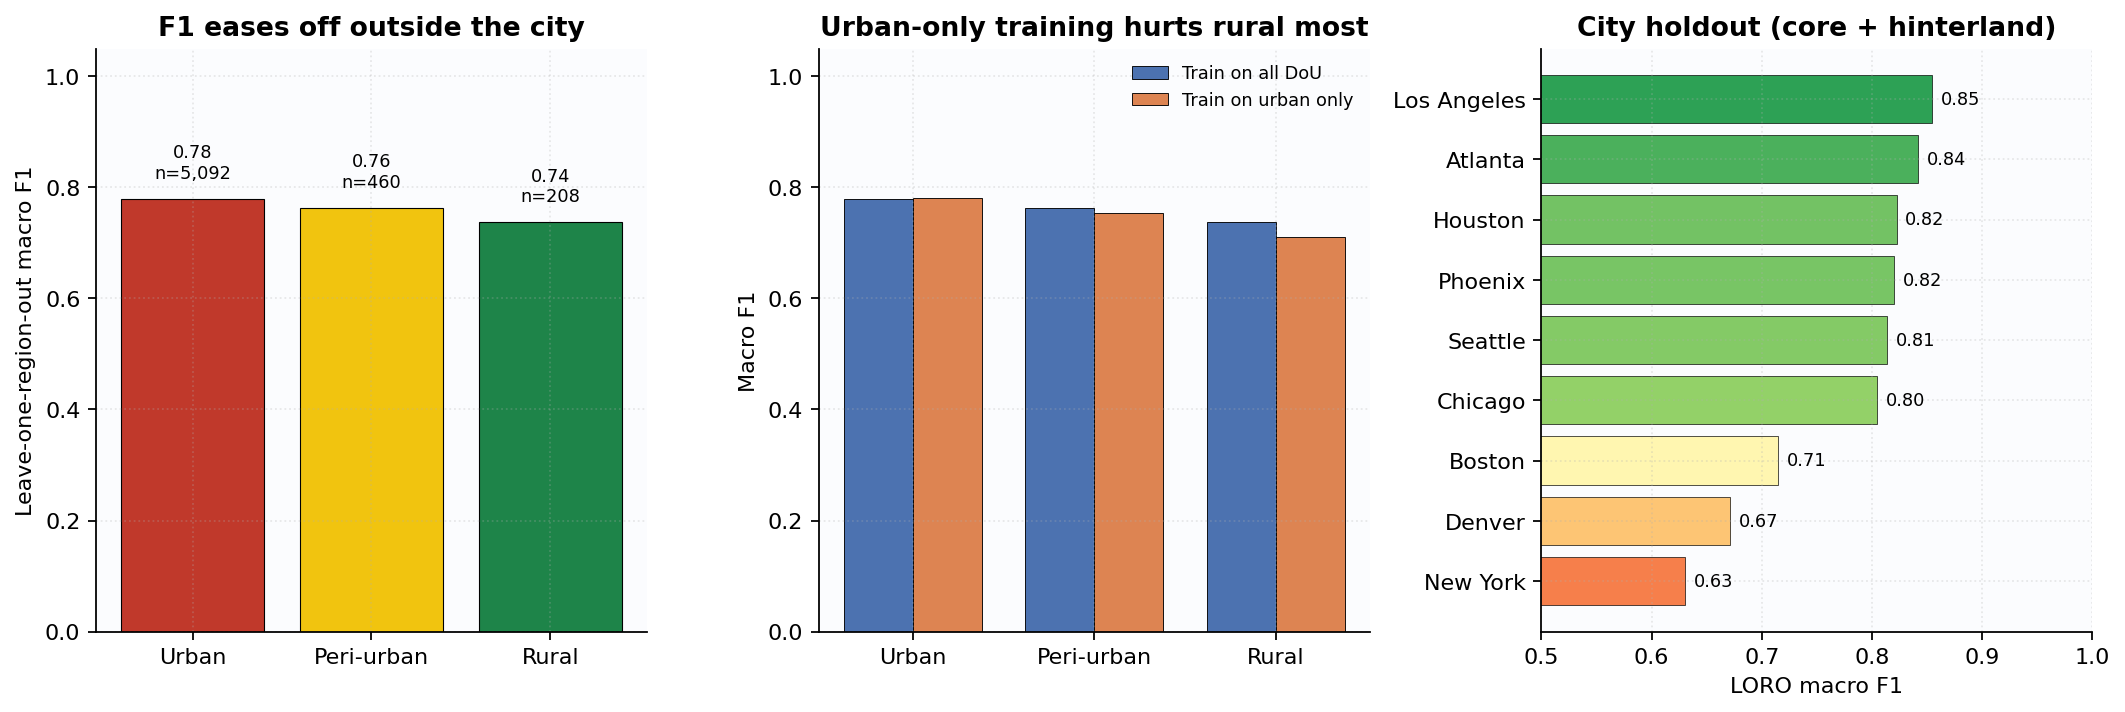

/data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/f1_by_dou_and_city.png


In [5]:
display(Image(filename=str(PLOTS["4_f1"])))
print(PLOTS["4_f1"])


## One-slide takeaway

1. **Downtown-only LORO ≠ urban/peri/rural story** — need hinterland.
2. **Label availability is the bigger DoU gap** (fill 35→14%) than classifier collapse.
3. **Report LORO F1 overall and by DoU going forward**; keep hinterland in the sample.
4. Do not treat unlabeled rural footprints as negatives.


In [6]:
# Optional: copy all four PNGs into a presentation folder
import shutil

present = OUT / "presentation_plots"
present.mkdir(exist_ok=True)
names = [
    ("01_core_is_urban.png", PLOTS["1_core"]),
    ("02_hinterland_maps_by_dou.png", PLOTS["2_maps"]),
    ("03_fill_rate_story.png", PLOTS["3_fill"]),
    ("04_f1_by_dou_and_city.png", PLOTS["4_f1"]),
]
for dest_name, src in names:
    dst = present / dest_name
    shutil.copy2(src, dst)
    print("Copied", dst)


Copied /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/presentation_plots/01_core_is_urban.png
Copied /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/presentation_plots/02_hinterland_maps_by_dou.png
Copied /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/presentation_plots/03_fill_rate_story.png
Copied /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_ghsl_dou/presentation_plots/04_f1_by_dou_and_city.png
